In [1]:
import os
import pandas as pd
import scanpy as sc
from lifelines import CoxPHFitter
import matplotlib.pyplot as plt

In [2]:
pth = os.path.join('..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'TCGA')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_ref = os.path.join(pth_data, 'refs', 'AnimalTFDBv4')
pth_out = os.path.join(pth, 'figures', 'TCGA')

In [3]:
event_col, t_col = 'PFI', 'PFI.time'
strata = 'cancer type abbreviation'

In [4]:
# select & deduplicate gliomas (LGG, GBM)
adata = sc.read_h5ad(os.path.join(pth_in, 'PANCAN.h5ad'))
adata = adata[adata.obs[strata].isin(['LGG', 'GBM'])].copy()
df_event = adata.obs[[event_col, t_col]].copy()
adata.obs[[event_col, t_col]] = df_event.astype(float)
adata = adata[~adata.obs[t_col].isnull()].copy()
adata = adata[adata.obs.sort_index().index].copy()
adata = adata[~adata.obs._PATIENT.duplicated()].copy()
adata

AnnData object with n_obs × n_vars = 668 × 60498
    obs: '_PATIENT', 'cancer type abbreviation', 'age_at_initial_pathologic_diagnosis', 'gender', 'race', 'ajcc_pathologic_tumor_stage', 'clinical_stage', 'histological_type', 'histological_grade', 'initial_pathologic_dx_year', 'menopause_status', 'birth_days_to', 'vital_status', 'tumor_status', 'last_contact_days_to', 'death_days_to', 'cause_of_death', 'new_tumor_event_type', 'new_tumor_event_site', 'new_tumor_event_site_other', 'new_tumor_event_dx_days_to', 'treatment_outcome_first_course', 'margin_status', 'residual_tumor', 'OS', 'OS.time', 'DSS', 'DSS.time', 'DFI', 'DFI.time', 'PFI', 'PFI.time', 'Redaction'
    uns: 'log1p'

In [5]:
# load mesencoder features, TFs
g = pd.read_csv(os.path.join(pth_feat, 'union.csv')).hsapiens
tf = pd.read_csv(os.path.join(pth_ref, 'Homo_sapiens_TF'), sep = '\t').Symbol
tf = tf.loc[tf.isin(g) & tf.isin(adata.var_names)].values

In [6]:
# select TFs by expression
X = pd.DataFrame(adata[:, tf].X.toarray(),
                 index = adata.obs_names,
                 columns = tf)
X = X.loc[:, (X.mean(axis = 0) > .25)]
adata.obs = adata.obs.join(X); adata

AnnData object with n_obs × n_vars = 668 × 60498
    obs: '_PATIENT', 'cancer type abbreviation', 'age_at_initial_pathologic_diagnosis', 'gender', 'race', 'ajcc_pathologic_tumor_stage', 'clinical_stage', 'histological_type', 'histological_grade', 'initial_pathologic_dx_year', 'menopause_status', 'birth_days_to', 'vital_status', 'tumor_status', 'last_contact_days_to', 'death_days_to', 'cause_of_death', 'new_tumor_event_type', 'new_tumor_event_site', 'new_tumor_event_site_other', 'new_tumor_event_dx_days_to', 'treatment_outcome_first_course', 'margin_status', 'residual_tumor', 'OS', 'OS.time', 'DSS', 'DSS.time', 'DFI', 'DFI.time', 'PFI', 'PFI.time', 'Redaction', 'SOX3', 'TBX3', 'ALX3', 'HOXA5', 'CEBPD', 'SOX2', 'HOXA1', 'PRRX2', 'PLAGL1', 'TCF15', 'MESP1', 'MSX1', 'ETV4', 'TBX6', 'GSC', 'ID1', 'PBX1', 'HOXC9', 'ZIC5', 'HOXA7', 'YBX1', 'HOXB7', 'NR2F2', 'POU5F1', 'FOXC1', 'RARG', 'EGR1', 'SNAI2', 'FLI1', 'TCF4', 'SOX9', 'TSHZ1', 'MYC', 'JUN', 'SOX6', 'SNAI1', 'RARB', 'HOXA9', 'IRX1', 'TCF

In [7]:
# fit proportional hazards model
cols = [strata, event_col, t_col] + \
        X.columns.values.tolist()
cph = CoxPHFitter().fit(adata.obs[cols],
    t_col, event_col, strata = strata)
df = cph.summary.sort_values(
        'coef', ascending = False)
df

/home/caleb/miniconda3/envs/survival/lib/python3.13/site-packages/lifelines/fitters/__init__.py:1280: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for stratum, df_ in df.groupby(strata):
/home/caleb/miniconda3/envs/survival/lib/python3.13/site-packages/lifelines/fitters/coxph_fitter.py:1868: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for stratum, stratified_X in X.groupby(self.strata):
/home/caleb/miniconda3/envs/survival/lib/python3.13/site-packages/lifelines/fitters/coxph_fitter.py:1868: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas.

,coef,exp(coef),se(coef),coef lower 95%,coef upper 95%,exp(coef) lower 95%,exp(coef) upper 95%,cmp to,z,p,-log2(p)
covariate,,,,,,,,,,,
SOX2,0.972094,2.643474,0.372038,0.242912,1.701275,1.274957,5.480933,0.0,2.612887,0.008978,6.799374
POU5F1,0.943072,2.567857,0.350312,0.256473,1.629670,1.292364,5.102193,0.0,2.692091,0.007101,7.137851
ZIC2,0.623347,1.865160,0.269073,0.095974,1.150720,1.100731,3.160466,0.0,2.316649,0.020523,5.606623
HOXC4,0.558661,1.748330,0.188283,0.189633,0.927689,1.208806,2.528658,0.0,2.967136,0.003006,8.377998
ZFP36L1,0.527398,1.694517,0.259486,0.018815,1.035981,1.018994,2.817868,0.0,2.032475,0.042106,4.569843
...,...,...,...,...,...,...,...,...,...,...,...
MESP2,-0.641340,0.526586,0.412433,-1.449694,0.167014,0.234642,1.181770,0.0,-1.555017,0.119942,3.059590
NFIB,-0.664405,0.514579,0.236414,-1.127769,-0.201042,0.323755,0.817878,0.0,-2.810345,0.004949,7.658692
TCF7L1,-0.850483,0.427209,0.258422,-1.356981,-0.343985,0.257437,0.708940,0.0,-3.291062,0.000998,9.968527


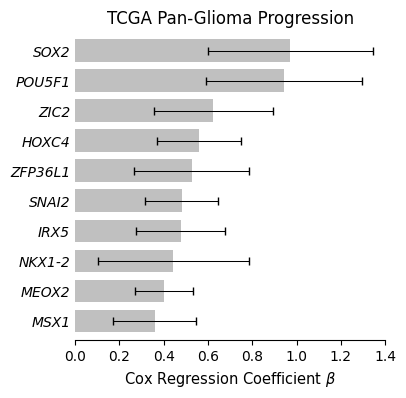

In [8]:
df_plt = df.head(10)

# plot top predictors
fig, ax = plt.subplots(1, 1, figsize = (4, 4))
df_plt.coef.plot(kind = 'barh', width = .75,
                 xerr = df_plt['se(coef)'],
                 color = 'silver', capsize = 3,
                 error_kw = {'linewidth' : .75},
                 ax = ax)

ax.set_xlim(0, 1.4)
ax.set_xlabel(r'Cox Regression Coefficient $\beta$', size = 10.5)
ax.set_ylabel('')

ax.tick_params('y', size = 0)
for lbl in ax.get_yticklabels():
    lbl.set_fontstyle('italic')

ax.set_title('TCGA Pan-Glioma Progression', size = 12)

for sp in ('top', 'right', 'left'):
    ax.spines[sp].set_visible(False)

ax.invert_yaxis()
fn = os.path.join(pth_out, 'progression.pdf')
plt.savefig(fn, bbox_inches = 'tight')